# CS570 — Lecture 6 Lab
## Data Preparation with Movie Ratings

Work in pairs, one notebook per pair, alongside the lecture. Each task follows the unit just taught. Complete code cells marked `...`. For explanation questions, double-click the question cell and write a brief answer below the prompt. Use results printed by the code as evidence; you do not need to copy them into prose.

Everything reads from `../data/movies/development`.

**The data.** `ratings_dev.dat` holds every rating made before 2001-01-01. The ratings made on or after that date form the production set. The instructor keeps it and scores your project models on it, so you never see it. `users_dev.dat` and `movies_dev.dat` are unchanged copies of the user and movie files. Only the ratings are split by time, because users and movies are lookup tables. They list all 6,040 users and all 3,883 movies, including some that have no rating in `ratings_dev.dat`. The ratings are split into train and test in Task 2.2 (the code is written for you); the word train refers only to that split.

**Names:**


# Part 1 — Understanding the Data

## Task 1.1 — Setup

In [1]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, LongType, StringType

spark = SparkSession.builder.appName("CS570 L06 Lab").getOrCreate()
print(spark.version)

# This data is for building the pipeline and the model. Later we test the model on production data it has not seen.
DATA_DIR = "../data/movies/development"

4.2.0


## Task 1.2 — Reading with the separator

Read `users_dev.dat` with the simplest possible call and look at the result.

In [2]:
users_raw_df = spark.read.csv(f"{DATA_DIR}/users_dev.dat")

users_raw_df.show(3, truncate=False)
print(users_raw_df.columns)

+-------------------+
|_c0                |
+-------------------+
|1::F::1::10::48067 |
|2::M::56::16::70072|
|3::M::25::15::55117|
+-------------------+
only showing top 3 rows
['_c0']


Fix the read. The `sep` option accepts a multi-character string.

In [3]:
users_sep_df = spark.read.csv(f"{DATA_DIR}/users_dev.dat", sep="::")

users_sep_df.show(3, truncate=False)
print(users_sep_df.dtypes)

+---+---+---+---+-----+
|_c0|_c1|_c2|_c3|_c4  |
+---+---+---+---+-----+
|1  |F  |1  |10 |48067|
|2  |M  |56 |16 |70072|
|3  |M  |25 |15 |55117|
+---+---+---+---+-----+
only showing top 3 rows
[('_c0', 'string'), ('_c1', 'string'), ('_c2', 'string'), ('_c3', 'string'), ('_c4', 'string')]


## Task 1.3 — Choosing a schema field

Most fields are supplied. You will write the complete `StructField` entry for `zip_code` in `users_schema`.

Before editing the schema, inspect the fifth column (`_c4`) of `users_sep_df` beyond the first few rows. Find at least one value that helps you decide how the field should be represented. Choose the field type and `nullable` value, then replace the placeholder in the next cell with the full `StructField` entry.

**Your evidence and reasoning:** Give one value you found. Explain what the field represents, why you chose its type, and what your `nullable` choice means.

**Your answer:** `02460` begins with zero, and `98107-2117` includes a hyphen. ZIP codes are identifiers rather than quantities, so `StringType()` preserves their values. The solution uses `nullable=True` to allow an unknown ZIP in future data.

In [4]:
ratings_schema = StructType([
    StructField("user_id",   IntegerType(), False),
    StructField("movie_id",  IntegerType(), False),
    StructField("rating",    IntegerType(), False),
    StructField("timestamp", LongType(),    True),
])

users_schema = StructType([
    StructField("user_id",    IntegerType(), False),
    StructField("gender",     StringType(),  False),
    StructField("age",        IntegerType(), False),
    StructField("occupation", IntegerType(), False),
    StructField("zip_code",   StringType(),  True),
])

movies_schema = StructType([
    StructField("movie_id", IntegerType(), False),
    StructField("title",    StringType(),  True),
    StructField("genres",   StringType(),  True),
])

In [5]:
ratings_df = spark.read.csv(f"{DATA_DIR}/ratings_dev.dat", sep="::", schema=ratings_schema)
users_df   = spark.read.csv(f"{DATA_DIR}/users_dev.dat",         sep="::", schema=users_schema)

ratings_df.show(3)
users_df.show(3)

+-------+--------+------+---------+
|user_id|movie_id|rating|timestamp|
+-------+--------+------+---------+
|   3031|     288|     4|970356559|
|   2389|     599|     4|974297915|
|   1121|     919|     4|974911173|
+-------+--------+------+---------+
only showing top 3 rows
+-------+------+---+----------+--------+
|user_id|gender|age|occupation|zip_code|
+-------+------+---+----------+--------+
|      1|     F|  1|        10|   48067|
|      2|     M| 56|        16|   70072|
|      3|     M| 25|        15|   55117|
+-------+------+---+----------+--------+
only showing top 3 rows


## Task 1.4 — Checking the values

Check the ranges and null counts of the columns you just read. If a value is unexpected, revisit the separator and schema before continuing.

In [6]:
rating_range = ratings_df.agg(F.min("rating"), F.max("rating")).first()
rating_range = (rating_range[0], rating_range[1])
genders = [r["gender"] for r in users_df.select("gender").distinct().collect()]
age_codes = sorted(r["age"] for r in users_df.select("age").distinct().collect())
n_null = ratings_df.filter(" OR ".join(f"{c} IS NULL" for c in ratings_df.columns)).count()

print(rating_range, genders, age_codes, n_null)

(1, 5) ['F', 'M'] [1, 18, 25, 35, 45, 50, 56] 0


## Task 1.5 — Reading and validating `movies_dev.dat`

Write the read routine using the separator and schema above. Check the row count and inspect titles beyond the first few rows to decide whether the parsed values are credible.

**(a)** Read `movies_dev.dat` with the separator and `movies_schema`. Do not set an encoding yet. Check the row count and inspect some titles.

In [7]:
movies_default_df = spark.read.csv(f"{DATA_DIR}/movies_dev.dat", sep="::", schema=movies_schema)

print(f"rows: {movies_default_df.count():,}")
movies_default_df.select("movie_id", "title").show(10, truncate=False)

rows: 3,883
+--------+----------------------------------+
|movie_id|title                             |
+--------+----------------------------------+
|1       |Toy Story (1995)                  |
|2       |Jumanji (1995)                    |
|3       |Grumpier Old Men (1995)           |
|4       |Waiting to Exhale (1995)          |
|5       |Father of the Bride Part II (1995)|
|6       |Heat (1995)                       |
|7       |Sabrina (1995)                    |
|8       |Tom and Huck (1995)               |
|9       |Sudden Death (1995)               |
|10      |GoldenEye (1995)                  |
+--------+----------------------------------+
only showing top 10 rows


**(b) Look beyond the first ten rows.** Show the fifteen longest titles with their length, longest first. Use a SQL query on a temporary view, or the DataFrame API.

In [8]:
movies_default_df.createOrReplaceTempView("movies")

longest_df = spark.sql("""
    SELECT movie_id, title, LENGTH(title) AS title_length
    FROM movies
    ORDER BY title_length DESC, movie_id
    LIMIT 15
""")

longest_df.show(truncate=False)

+--------+----------------------------------------------------------------------------------+------------+
|movie_id|title                                                                             |title_length|
+--------+----------------------------------------------------------------------------------+------------+
|3636    |Those Who Love Me Can Take the Train (Ceux qui m'aiment prendront le train) (1998)|82          |
|797     |Old Lady Who Walked in the Sea, The (Vieille qui marchait dans la mer, La) (1991) |81          |
|63      |Don't Be a Menace to South Central While Drinking Your Juice in the Hood (1996)   |79          |
|363     |Wonderful, Horrible Life of Leni Riefenstahl, The (Die Macht der Bilder) (1993)   |79          |
|2239    |Swept Away (Travolti da un insolito destino nell'azzurro mare d'Agosto) (1975)    |78          |
|793     |My Life and Times With Antonin Artaud (En compagnie d'Antonin Artaud) (1993)      |76          |
|750     |Dr. Strangelove or: How I L

**(c) Measure it.** Count the titles in the whole column that contain the odd character, and show a few.

In [9]:
bad_df = movies_default_df.filter(F.col("title").contains("�"))

print(bad_df.count())
bad_df.show(10, truncate=False)

50
+--------+-----------------------------------------------------------------+-----------------------------+
|movie_id|title                                                            |genres                       |
+--------+-----------------------------------------------------------------+-----------------------------+
|73      |Mis�rables, Les (1995)                                           |Drama|Musical                |
|570     |Slingshot, The (K�disbellan ) (1993)                             |Comedy|Drama                 |
|582     |Metisse (Caf� au Lait) (1993)                                    |Comedy                       |
|649     |Cold Fever (� k�ldum klaka) (1994)                               |Comedy|Drama                 |
|1117    |Eighth Day, The (Le Huiti�me jour ) (1996)                       |Drama                        |
|1149    |JLG/JLG - autoportrait de d�cembre (1994)                        |Documentary|Drama            |
|1176    |Double Life of Veronique

**Why might title characters be damaged even though the read succeeds and the row count is right?**

**Your answer:** The file bytes may have been decoded with the wrong character encoding. Row boundaries can still parse correctly.

**(d) Diagnose and repair.** `movies_dev.dat` uses Latin-1 (`ISO-8859-1`), while the default decoder uses UTF-8. Read it again with the correct encoding, then repeat the damaged-title check.

In [10]:
movies_latin1_df = (spark.read
                 .option("encoding", "ISO-8859-1")
                 .csv(f"{DATA_DIR}/movies_dev.dat", sep="::", schema=movies_schema))

n_bad_latin1 = movies_latin1_df.filter(F.col("title").contains("�")).count()
print(f"corrected rows: {movies_latin1_df.count():,}   damaged titles: {n_bad_latin1}")
movies_latin1_df.filter(F.col("movie_id").isin(2585, 3652)).select("movie_id", "title").show(truncate=False)

corrected rows: 3,883   damaged titles: 0
+--------+-----------------------------------------------------------------------+
|movie_id|title                                                                  |
+--------+-----------------------------------------------------------------------+
|2585    |Lovers of the Arctic Circle, The (Los Amantes del Círculo Polar) (1998)|
|3652    |City of the Living Dead (Paura nella città dei morti viventi) (1980)   |
+--------+-----------------------------------------------------------------------+



**What did the row count fail to detect? Name one downstream problem that corrupted titles could cause.**

**Your answer:** It missed corrupted text values. A wrong title can create a spurious group or make a join on title fail.

## Task 1.6 — Counts

Compute the number of movies in the catalog and the number of movies that have at least one rating. Then explain why the two numbers differ.

In [11]:
n_ratings = ratings_df.count()
n_users = users_df.count()
n_movies = movies_latin1_df.count()
n_rated_movies = ratings_df.select("movie_id").distinct().count()
n_unrated = n_movies - n_rated_movies

print(f"ratings: {n_ratings:,}   users: {n_users:,}   movies: {n_movies:,}")
print(f"rated movies: {n_rated_movies:,}   unrated movies: {n_unrated:,}")

ratings: 904,757   users: 6,040   movies: 3,883
rated movies: 3,678   unrated movies: 205


**Match each number (3,883 and 3,678) to what it counts.**

**Your answer:** 3,883 is the number of rows in `movies_dev.dat`, which is the number of movies catalogued. 3,678 is the number of distinct movies that have at least one rating in the ratings file. The other 205 movies have no rating there.

## Task 1.7 — Defining the target and baseline

The target is defined before any feature is explored, because a column carries signal only relative to a target. The target is `high_rating`: 1 when the rating is 4 or higher, otherwise 0. No train/test split exists yet, so the numbers below are descriptive: they summarise the ratings.

In [12]:
rated_df = ratings_df.withColumn("high_rating", F.when(F.col("rating") >= 4, 1).otherwise(0))
n_rows = rated_df.count()
balance_df = (rated_df.groupBy("high_rating").count()
           .withColumn("share", F.col("count") / n_rows)
           .orderBy("high_rating"))

balance_df.show()

share_pos = rated_df.agg(F.avg("high_rating")).first()[0]
baseline_acc = max(share_pos, 1 - share_pos)

print(f"{share_pos:.4f}   {baseline_acc:.4f}")

+-----------+------+-------------------+
|high_rating| count|              share|
+-----------+------+-------------------+
|          0|381392|0.42154081151071504|
|          1|523365|  0.578459188489285|
+-----------+------+-------------------+

0.5785   0.5785


**The baseline uses no feature at all. Why is its accuracy the number a model has to beat, and what is wrong with using 50% as the bar?**

**Your answer:** The majority class is 1, and always predicting 1 is correct on 0.5785 of the rows without using any column. A model that scores lower than that is worse than a constant prediction. The classes are unbalanced, so 50% is too low a bar: a model at 55% would beat a coin flip and still lose to predicting 1 for every row.

**Suppose the threshold were `rating >= 5` instead of `rating >= 4`. What would change for the class balance and the baseline, and why must the threshold be fixed before any column is compared with the target?**

**Your answer:** Only a rating of 5 would be positive, which is 23% of the rows. The positive class becomes the minority, the majority class becomes 0, and the baseline rises to about 0.77, so a model needs a higher accuracy to show any signal. The threshold defines the target, and every comparison of a column with the target depends on it: changing the threshold after the comparisons were made would change every one of them.

## Task 1.8 — Explore average ratings by group

Join the three tables. `join` defaults to an inner join.

In [13]:
movies_df = movies_latin1_df

df = ratings_df.join(users_df, "user_id").join(movies_df, "movie_id")

print(f"Rows: {df.count():,}")

Rows: 904,757


In [14]:
by_gender_df = (df.groupBy("gender")
               .agg(F.avg("rating").alias("avg_rating"), F.count("*").alias("n")))

by_gender_df.show()

+------+------------------+------+
|gender|        avg_rating|     n|
+------+------------------+------+
|     F|3.6320550272819374|220109|
|     M|3.5769972306937285|684648|
+------+------------------+------+



A movie carries several genres in one pipe-separated string. Split it and give each genre its own row.

In [15]:
exploded_df = df.withColumn("genre", F.explode(F.split("genres", "\\|")))

exploded_df.select("title", "genre").show(5, truncate=False)

+---------------------------+----------+
|title                      |genre     |
+---------------------------+----------+
|Natural Born Killers (1994)|Action    |
|Natural Born Killers (1994)|Thriller  |
|Wild Bunch, The (1969)     |Western   |
|Wizard of Oz, The (1939)   |Adventure |
|Wizard of Oz, The (1939)   |Children's|
+---------------------------+----------+
only showing top 5 rows


In [16]:
by_genre_df = (exploded_df.groupBy("genre")
            .agg(F.avg("rating").alias("avg_rating"), F.count("*").alias("n"))
            .orderBy(F.desc("avg_rating")))

by_genre_df.show(20)

+-----------+------------------+------+
|      genre|        avg_rating|     n|
+-----------+------------------+------+
|  Film-Noir| 4.079831932773109| 16898|
|Documentary|3.9410747730874514|  6941|
|        War|3.9022472264246093| 63456|
|      Drama| 3.774272362313386|318840|
|      Crime|3.7167777288247605| 72632|
|  Animation|3.6997252958845728| 38951|
|    Mystery|3.6711103841225703| 36681|
|    Musical| 3.669015964546959| 37458|
|    Western|3.6413380244709344| 19043|
|    Romance| 3.615235134084726|133796|
|   Thriller|3.5812102739686416|172903|
|     Comedy| 3.533001965809839|321496|
|     Action|3.5017211559451247|238212|
|  Adventure| 3.487543509088565|124112|
|     Sci-Fi|3.4775165143580793|146085|
|    Fantasy| 3.455756167322131| 33564|
| Children's| 3.431260555811454| 65130|
|     Horror| 3.225913953887522| 69916|
+-----------+------------------+------+



**Which grouping shows a larger spread in mean rating: gender or genre? Why is that spread only a clue, rather than proof that a column will improve predictions?**

**Your answer:**

**Plot the group means.** Complete `plot_group_means` so that it draws one bar per group, then call it on both tables. You will use it again for your assigned variable.

In [50]:
%pip install matplotlib

  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------- ----------------------------- 2.1/8.2 MB 11.7 MB/s eta 0:00:01
   --------------------- ------------------ 4.5/8.2 MB 11.2 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.2 MB 10.4 MB/s eta 0:00:01
   -------------------------------------- - 7.9/8.2 MB 10.3 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 9.1 MB/s  0:00:00
Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl (221 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.6 MB ? eta -:--:--
   -------------------------------------- - 1.6/1.6 MB 4.9 MB/s eta 0:00:01
   ---------------------------------------- 1.6/1.6 MB 4.4 MB/s  0:00:00
   ----

In [67]:
import matplotlib.pyplot as plt

def plot_group_means(means_df, title):

    # bar chart with one bar per group, showing the mean rating of the group
    rows = means_df.collect()
    labels = [str(r[0]) for r in rows]  # the group of each row, as text
    heights = [r[1] for r in rows] # the avg_rating of each row

    plt.figure(figsize=(14, 4))
    plt.bar(labels, heights)     # labels on the x axis, heights on the y axis
    plt.ylim(1, 5)
    plt.xticks(rotation=90, fontsize=7)
    plt.ylabel("average rating")
    plt.title(title)
    plt.grid()
    plt.show()

In [52]:
rows = by_gender_df.collect()
rows

[Row(gender='F', avg_rating=3.6320550272819374, n=220109),
 Row(gender='M', avg_rating=3.5769972306937285, n=684648)]

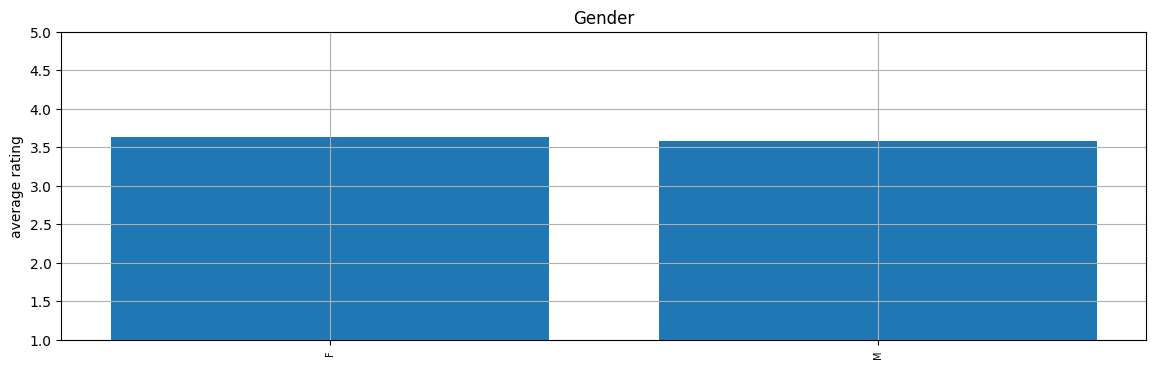

In [68]:
plot_group_means(by_gender_df, "Gender")

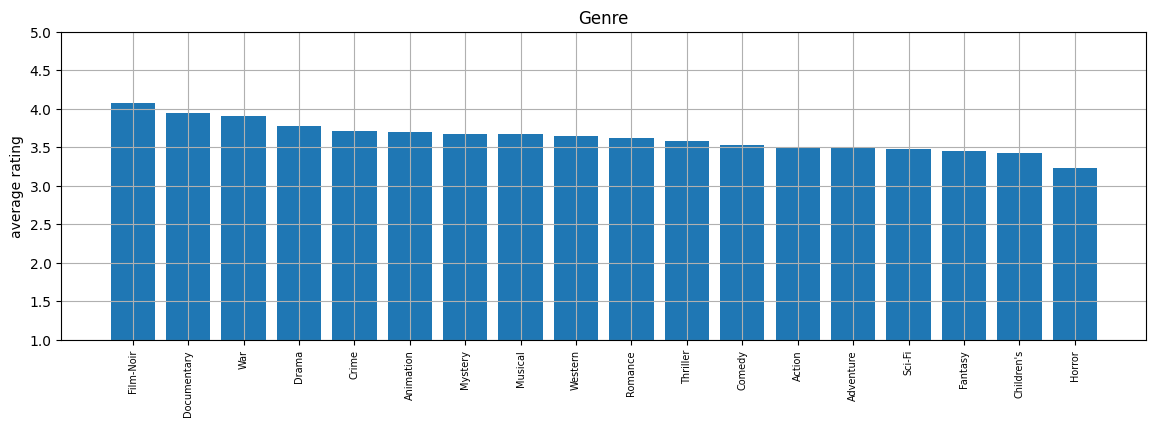

In [69]:
plot_group_means(by_genre_df, "Genre")

**Derive a column.** A movie's release year is not a column of its own: it is the four digits in parentheses at the end of `title`. Add it to `df` as `release_year`, an integer. Then check that no value is null, and show the earliest and the latest year.

In [70]:
df = df.withColumn("release_year", F.substring("title", -5, 4))    # the four digits in parentheses at the end of title, as an integer

print(df.filter(F.col("release_year").isNull()).count())
print(df.agg(F.min("release_year"), F.max("release_year")).first())

0
Row(min(release_year)='1919', max(release_year)='2000')


In [71]:
def group_means(df, key):

    # mean rating and number of ratings for each value of the key column
    means_df = (df.groupBy(key)
                  .agg(F.avg("rating").alias("avg_rating"), F.count("*").alias("n")))
    means_df = means_df.orderBy(key)

    return means_df

def spread(means_df, min_n=1000):

    # gap between the highest and the lowest group mean, over groups with at least min_n ratings
    big_df = means_df.filter(F.col("n") >= min_n)
    gap = big_df.agg(F.max("avg_rating") - F.min("avg_rating")).first()[0]

    return round(gap, 3)

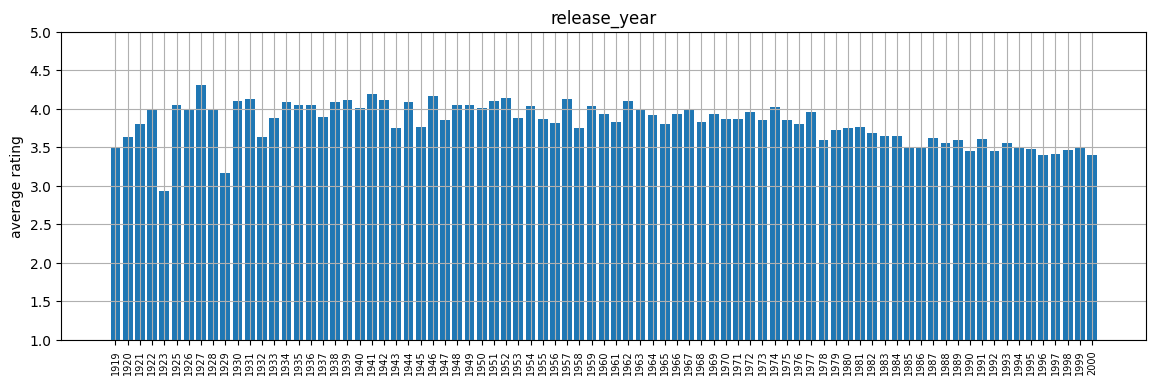

In [72]:
by_year_df = group_means(df, "release_year")
plot_group_means(by_year_df, "release_year")

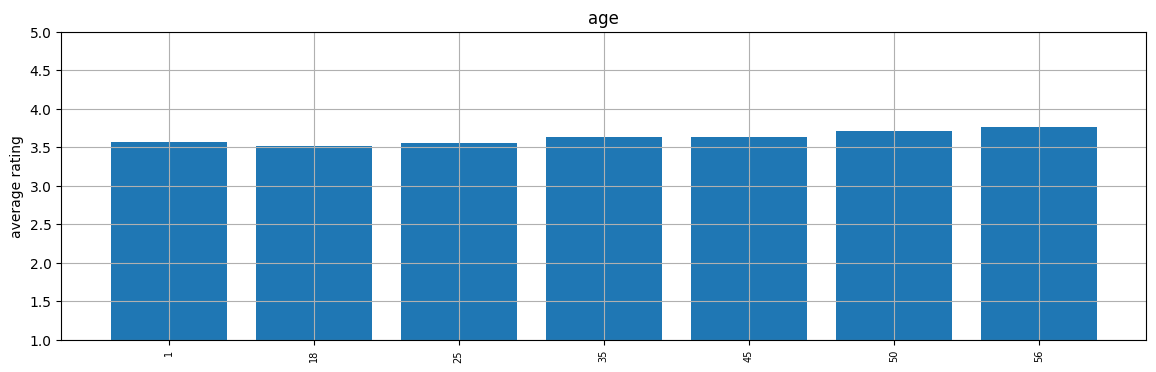

In [73]:
by_age_df = group_means(df, "age")
plot_group_means(by_age_df, "age")

## Task 1.9 — Correlation

Ten points where `y` rises with `x`, plus noise.

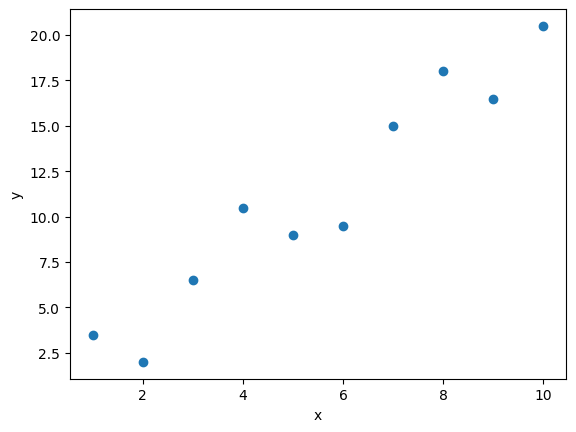

In [74]:
import matplotlib.pyplot as plt

noisy_df = spark.createDataFrame(
    [(1, 3.5), (2, 2.0), (3, 6.5), (4, 10.5), (5, 9.0), (6, 9.5), (7, 15.0), (8, 18.0), (9, 16.5), (10, 20.5)],
    ["x", "y"])

points = noisy_df.collect()
plt.scatter([r["x"] for r in points], [r["y"] for r in points])
plt.xlabel("x")
plt.ylabel("y")
plt.show()

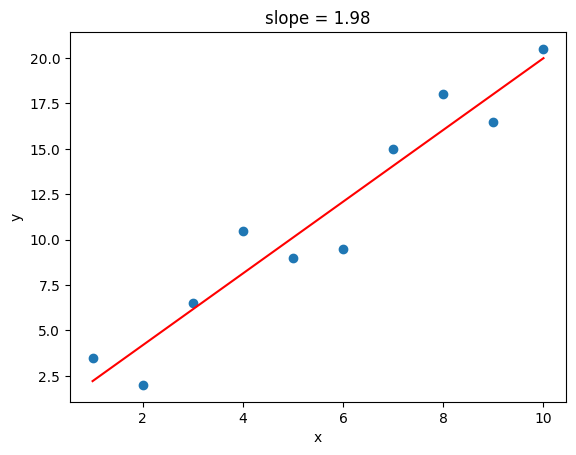

In [75]:
import numpy as np

def fit_line_and_plot(df, size=36, alpha=1.0):

    # scatter plot of the points in df (columns x and y) with the least-squares line drawn through them
    rows = df.collect()
    x = np.array([r["x"] for r in rows], dtype=float)
    y = np.array([r["y"] for r in rows], dtype=float)

    slope, intercept = np.polyfit(x, y, 1)

    plt.scatter(x, y, s=size, alpha=alpha)
    plt.plot(x, slope * x + intercept, color="red")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"slope = {slope:.2f}")
    plt.show()

fit_line_and_plot(noisy_df)

In [77]:
corr_noisy = noisy_df.stat.corr("x", "y") # the Pearson correlation of x and y
print(corr_noisy)
 


0.9600617778021263


Ten points where `y` follows `x` squared, plus noise.

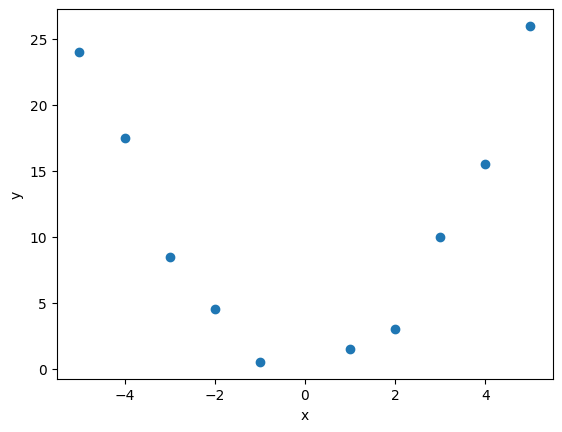

In [78]:
toy_df = spark.createDataFrame(
    [(-5, 24.0), (-4, 17.5), (-3, 8.5), (-2, 4.5), (-1, 0.5), (1, 1.5), (2, 3.0), (3, 10.0), (4, 15.5), (5, 26.0)],
    ["x", "y"])

toy_points = toy_df.collect()
plt.scatter([r["x"] for r in toy_points], [r["y"] for r in toy_points])
plt.xlabel("x")
plt.ylabel("y")
plt.show()

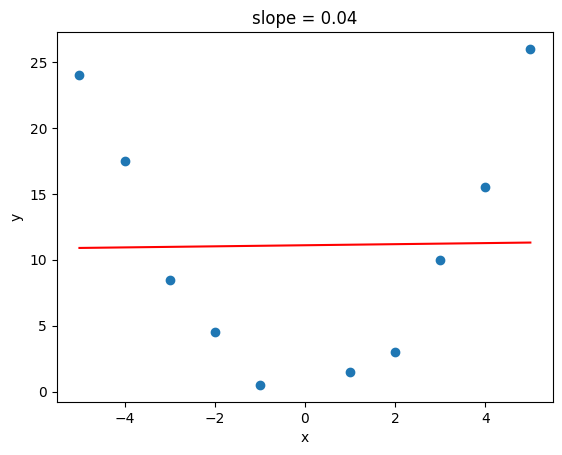

In [79]:
fit_line_and_plot(toy_df)

In [80]:
corr_xy = toy_df.stat.corr("x", "y") # the Pearson correlation of x and y
print(corr_xy)

0.015458168399373291


In [82]:
toy_sq_df = toy_df.withColumn("x_sq", F.col("x") * F.col("x"))  # toy_df with a new column x_sq equal to x * x
corr_x_sq_y = toy_sq_df.stat.corr("x_sq", "y") # the Pearson correlation of x_sq and y
print(corr_x_sq_y)



0.9952347524740776


**`y` follows `x` squared, plus noise. Explain `corr_xy`, and say what `corr_x_sq_y` shows about how the feature should be represented.**

**Your answer:**

# Part 2 — Building the Modeling Dataset

Run all the cells above first, so that `ratings_df`, `users_df` and `df` exist.

## Task 2.1 — Generating features

Aggregate ratings to one row per user, then join those features back to the rating rows. Inspect the resulting columns and sample values.

In [ ]:
user_feats_df = df.groupBy("user_id").agg(
    F.avg("rating").alias("user_avg_rating"),
    F.count("*").alias("user_rating_count")
)

with_user_feats_df = df.join(user_feats_df, on="user_id", how="left")

print("Number of columns:", len(with_user_feats_df.columns))
with_user_feats_df.select("user_id", "movie_id", "rating", "user_avg_rating", "user_rating_count").show(5)

# one row per user_id: avg_rating as user_avg_rating, row count as user_rating_count
# df joined with user_feats_df on user_id



Number of columns: 13
+-------+--------+------+------------------+-----------------+
|user_id|movie_id|rating|   user_avg_rating|user_rating_count|
+-------+--------+------+------------------+-----------------+
|   4028|    3544|     3|3.4990689013035383|              537|
|   1121|     919|     4| 4.073170731707317|              123|
|   5795|    2375|     1|3.0534591194968552|             1272|
|   3031|     288|     4|             3.904|              500|
|   2901|    1965|     5| 4.289156626506024|              249|
+-------+--------+------+------------------+-----------------+
only showing top 5 rows


In [87]:
with_user_feats_df.withColumn("user_rating_delta", F.col("rating") - F.col("user_avg_rating"))

DataFrame[user_id: int, movie_id: int, rating: int, timestamp: bigint, gender: string, age: int, occupation: int, zip_code: string, title: string, genres: string, release_year: string, user_avg_rating: double, user_rating_count: bigint, user_rating_delta: double]

**The same for movies.** Aggregate the ratings to one row per movie, then join those features back to the rating rows.

In [88]:
movie_feats_df = df.groupBy("movie_id").agg(F.avg("rating").alias("movie_avg_rating"), F.count("*").alias("movie_popularity"))
     # one row per movie_id: avg_rating as movie_avg_rating, row count as movie_popularity

with_movie_feats_df = df.join(movie_feats_df, on="movie_id", how="left")             # df joined with movie_feats_df on movie_id

print("Number of columns:", len(with_movie_feats_df.columns))
with_movie_feats_df.select("user_id", "movie_id", "rating", "movie_avg_rating", "movie_popularity").show(5)

Number of columns: 13
+-------+--------+------+------------------+----------------+
|user_id|movie_id|rating|  movie_avg_rating|movie_popularity|
+-------+--------+------+------------------+----------------+
|   2389|     599|     4| 4.101769911504425|             226|
|   1121|     919|     4|  4.25062656641604|            1596|
|   5795|    2375|     1|2.9069148936170213|             376|
|   2901|    1965|     5| 3.691983122362869|             711|
|   3031|     288|     4| 3.134069400630915|             634|
+-------+--------+------+------------------+----------------+
only showing top 5 rows


## Task 2.2 — Measuring the leak

Build the same feature, the average rating of each movie, in two ways and compare them. The data is split **once**, by time: the ratings before December 2000 train and the ratings from December 2000 test. The split is written for you.

**The leaky pipeline.** The movie features from Task 2.1 were computed over **all** ratings. Join them onto every rating, and only then separate the train and test rows.

In [89]:
from datetime import datetime, timezone

df = ratings_df.withColumn("high_rating", F.when(F.col("rating") >= 4, 1).otherwise(0))   # the target from Task 1.7, added here again so that this task runs on its own

# the split, once: the ratings from December 2000 are the test rows, everything before them trains
cutoff = int(datetime(2000, 12, 1, tzinfo=timezone.utc).timestamp())   # 1 December 2000, in seconds since 1970
train_raw_df = df.filter(F.col("timestamp") < cutoff)
test_raw_df = df.filter(F.col("timestamp") >= cutoff)

print(f"Train rows: {train_raw_df.count():,}   test rows: {test_raw_df.count():,}")

Train rows: 791,270   test rows: 113,487


In [93]:
# ---- LEAKY: aggregate over everything, separate train and test afterwards ----
leaky_movie_df = movie_feats_df      # the movie features from Task 2.1, computed over all ratings
leaky_df = df.join(leaky_movie_df, on="movie_id")           # df with leaky_movie_df joined on movie_id
leaky_train_df = leaky_df.filter(F.col("timestamp") < cutoff)  # the rows of leaky_df with timestamp < cutoff
leaky_test_df = leaky_df.filter(F.col("timestamp") >= cutoff)   # the rows of leaky_df with timestamp >= cutoff

leaky_test_df.select("movie_id", "rating", "user_id", "movie_avg_rating", "movie_popularity").show(5)

+--------+------+-------+------------------+----------------+
|movie_id|rating|user_id|  movie_avg_rating|movie_popularity|
+--------+------+-------+------------------+----------------+
|    1580|     2|    100|3.7357172215371968|            2433|
|    1580|     4|    212|3.7357172215371968|            2433|
|    1580|     4|    496|3.7357172215371968|            2433|
|    1580|     4|    480|3.7357172215371968|            2433|
|     471|     5|    549| 3.619744058500914|             547|
+--------+------+-------+------------------+----------------+
only showing top 5 rows


**Which ratings went into the `movie_avg_rating` of a test row?**

**Your answer:**

In [95]:
leaky_train_df.filter(F.col("movie_id") ==  1500).show()

+--------+-------+------+---------+-----------+------------------+----------------+
|movie_id|user_id|rating|timestamp|high_rating|  movie_avg_rating|movie_popularity|
+--------+-------+------+---------+-----------+------------------+----------------+
|    1500|   2063|     4|974660280|          1|3.8163653663177928|            1051|
|    1500|   3609|     3|966614927|          0|3.8163653663177928|            1051|
|    1500|   2897|     4|971934091|          1|3.8163653663177928|            1051|
|    1500|   2148|     4|974623349|          1|3.8163653663177928|            1051|
|    1500|   2414|     4|974917113|          1|3.8163653663177928|            1051|
|    1500|   1132|     5|974888435|          1|3.8163653663177928|            1051|
|    1500|   2302|     4|974497040|          1|3.8163653663177928|            1051|
|    1500|   3562|     3|966789813|          0|3.8163653663177928|            1051|
|    1500|   3790|     4|966039425|          1|3.8163653663177928|          

## Task 2.3 — The split-first pipeline

Compute the movie averages from the **training rows only**, then attach them to both sets. Choose the type of join yourself; the row check below shows whether it was right.

In [94]:
good_movie_df = ...     # aggregate train_raw_df by movie_id: movie_avg_rating and movie_popularity
train_df = ...          # train_raw_df with good_movie_df joined on movie_id
test_df = ...           # test_raw_df with good_movie_df joined on movie_id

print(f"Rows in train_df: {train_df.count():,}   test_df: {test_df.count():,}   leaky_test_df: {leaky_test_df.count():,}")

AttributeError: 'ellipsis' object has no attribute 'count'

In [ ]:
print(f"test_raw_df rows: {test_raw_df.count():,}   test_df rows after the join: {test_df.count():,}")

**Check row preservation:** `test_raw_df` and `test_df` should have the same number of rows. If they differ, inspect the join and fix it before continuing.

**Compare a low-count movie.** Find a movie with fewer than 10 ratings in total that appears in both the test rows and `good_movie_df`. Use the code below to compare its `movie_avg_rating` in the two pipelines.

In [ ]:
few_df = ...      # rows of leaky_movie_df with movie_popularity below 10, whose movie_id is in good_movie_df and in test_raw_df, sorted by movie_id
few_df.show(5)

small_movie_id = ...     # one movie_id from that list

In [ ]:
def compare(movie_id):
    leaky_val = leaky_movie_df.filter(F.col("movie_id") == movie_id).first()
    good_val = good_movie_df.filter(F.col("movie_id") == movie_id).first()
    print(f"movie_id {movie_id}: total ratings {leaky_val['movie_popularity']}")
    print(f"  leaky {leaky_val['movie_avg_rating']:.4f}   split-first {good_val['movie_avg_rating']:.4f}"
          f"   difference {leaky_val['movie_avg_rating'] - good_val['movie_avg_rating']:.4f}")

compare(small_movie_id)

**Compare a popular movie.** Repeat the comparison for a movie with more than 1,000 ratings.

In [ ]:
big_movie_id = ...      # one movie_id whose movie_popularity in leaky_movie_df is above 1,000, the first in movie_id order

compare(big_movie_id)

**Why is the difference usually more noticeable for the low-count movie? Explain using group size and the contribution of one rating, `1/n`.**

**Your answer:**

**Find test rows without movie features.** The split-first pipeline used a left join, so a movie absent from the training rows leaves null features on its test rows.

In [ ]:
n_null = test_df.filter(F.col("movie_avg_rating").isNull()).count()
n_test = test_df.count()

print(f"Test rows without movie features: {n_null:,} of {n_test:,} ({100 * n_null / n_test:.3f}%)")

**Why does the leaky pipeline have zero such rows?**

**Your answer:**

**What would an inner join remove from the test set, and how could that make the reported score look better without improving the model?**

**Your answer:**

**Check the time split and baseline.** Confirm that the training rows precede the test rows, then measure baseline accuracy on the test rows.

In [ ]:
latest_train = ...    # the largest timestamp in train_raw_df
earliest_test = ...   # the smallest timestamp in test_raw_df

print("All training rows precede all test rows:", latest_train < earliest_test)

test_pos = ...        # the share of rows with high_rating = 1 in test_raw_df
test_baseline = ...   # the accuracy of always predicting the more common class, measured on test_raw_df

print(f"Baseline accuracy on the test rows: {test_baseline:.4f}")

**Why should a model evaluated on `test_df` be compared with the test-row baseline rather than the baseline over all ratings from Task 1.7?**

**Your answer:**

## Task 2.4 — Encoding categorical features

Add the user columns to the split-first data, then encode gender and build the occupation encoding as a pipeline.

In [ ]:
train_users_df = train_df.join(users_df, "user_id")
test_users_df = test_df.join(users_df, "user_id")

gender_enc = ...     # 1 when gender is "F", otherwise 0

train_users_df = train_users_df.withColumn("gender_encoded", gender_enc)
test_users_df = test_users_df.withColumn("gender_encoded", gender_enc)

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

train_users_df = train_users_df.withColumn("occ", F.col("occupation").cast("string"))
test_users_df = test_users_df.withColumn("occ", F.col("occupation").cast("string"))

indexer = StringIndexer(inputCol="occ", outputCol="occ_idx")
encoder = OneHotEncoder(inputCol="occ_idx", outputCol="occ_vec")
assembler_enc = VectorAssembler(inputCols=["age", "gender_encoded", "occ_vec"], outputCol="features")

pipeline = ...          # a Pipeline of the three stages
pipeline_model = ...    # the pipeline fitted so that nothing is learned from test_users_df
train_enc_df = ...         # train_users_df through pipeline_model
test_enc_df = ...          # test_users_df through pipeline_model

print("Length of the feature vector:", train_enc_df.select("features").first()[0].size)

**Why is the pipeline fitted on training rows and then used to transform test rows?**

**Your answer:**

## Task 2.5 — Missing data and cold start

The left join left null features on the test rows. Find them, then fill them with values from the training rows and keep a flag.

In [ ]:
global_mean = train_raw_df.agg(F.avg("rating")).first()[0]

cold_df = ...            # the rows of test_df where movie_avg_rating is null
print("Test rows with a missing movie average:", cold_df.count())

test_filled_df = ...     # test_df with movie_avg_rating filled with global_mean, movie_popularity filled with 0,
                      # and a column movie_missing that is 1 for the rows that were null, otherwise 0
test_filled_df.select("movie_id", "movie_avg_rating", "movie_popularity", "movie_missing").filter("movie_missing = 1").show(3)

**Why keep `movie_missing` after filling a missing movie average with the training mean?**

**Your answer:**

## Task 2.6 — Column audit

Everything in the assembler's `inputCols` list is a predictor: the assembler builds the feature vector from exactly those columns. Review the list below and remove columns that must not be predictors. IDs can remain in the DataFrame for joins without being included in `inputCols`.

In [ ]:
input_cols = ["user_id", "movie_avg_rating", "movie_popularity", "gender_encoded", "age", "rating"]

not_allowed = {"user_id", "movie_id", "rating", "high_rating", "timestamp"}

bad = ...             # the entries of input_cols that are in not_allowed
input_cols = ...      # input_cols without them

print("Removed:", bad)
print("Remaining:", input_cols)

**Why is each removed column not allowed?**

**Your answer:**

## Task 2.7 — Comparing the pipelines

Fit the same logistic regression on two versions of the movie features and score each one on its own test rows. The scoring function is written for you.

In [ ]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# test_filled_df comes from Task 2.5: movies without a training rating got the global training mean and a count of 0

assembler = VectorAssembler(inputCols=["movie_avg_rating", "movie_popularity"], outputCol="features")
evaluator = BinaryClassificationEvaluator(labelCol="high_rating", metricName="areaUnderROC")

def auc(fit_df, score_df):
    model = LogisticRegression(featuresCol="features", labelCol="high_rating", maxIter=50).fit(assembler.transform(fit_df))
    return evaluator.evaluate(model.transform(assembler.transform(score_df)))

In [ ]:
leaky_auc = ...     # fitted on leaky_train_df, scored on leaky_test_df
split_auc = ...     # fitted on train_df, scored on test_filled_df

print(f"leaky {leaky_auc:.4f}   split-first {split_auc:.4f}")

**Which of the two numbers measures how the model will do on new ratings, and why?**

**Your answer:**

**Why can a small AUC gap still matter, and in what setting might the gap be larger?**

**Your answer:**

## Appendix task — The second leak

The split-first training rows still contain their own rating inside their own `movie_avg_rating`.

**(a)** A correlation near 1 between a feature and the rating it should predict is a warning. Compare the correlation of `rating` with `movie_avg_rating` on the leaky test rows and on the split-first test rows.

In [ ]:
corr_leaky = ...    # Pearson correlation of rating and movie_avg_rating in leaky_test_df
corr_split = ...    # the same in test_df, after dropping the rows where movie_avg_rating is null

print(f"leaky: {corr_leaky:.4f}   split-first: {corr_split:.4f}")

**Which is higher, and why does that make the leaky one untrustworthy?**

**Your answer:**

**(b)** Remove the second leak from the training rows. For each training row, replace `movie_avg_rating` with the average of the movie's **other** training ratings, `(S - r) / (n - 1)`, where `S = movie_avg_rating * movie_popularity` is the sum of the movie's training ratings, `r` is the row's own rating and `n = movie_popularity` is the number of the movie's training ratings. A movie with `movie_popularity = 1` gets the global training mean.

In [ ]:
train_loo_df = ...     # train_df with movie_avg_rating replaced by the leave-one-out average, and movie_popularity reduced by 1

print(f"self-included: {train_df.stat.corr('rating', 'movie_avg_rating'):.4f}   "
      f"leave-one-out: {train_loo_df.stat.corr('rating', 'movie_avg_rating'):.4f}")

**Why does leave-one-out change the training correlation? What was included in each training row’s earlier feature?**

**Your answer:**

In [ ]:
loo_auc = ...     # fitted on train_loo_df, scored on test_filled_df, with the auc function from Task 2.7

print(f"split-first {split_auc:.4f}   leave-one-out {loo_auc:.4f}")

**Why might test AUC stay nearly the same after fixing self-inclusion in the training features?**

**Your answer:**